# PyMC-15 : Processus Gaussiens et frontières non linéaires

**Navigation** : [Index](../README.md) | [<< PyMC-14](PyMC-14-Recommenders.ipynb) | [PyMC-16 >>](PyMC-16-Kalman-Filter.ipynb)

**Équivalent Infer.NET** : [Infer-15-Sparse-Gaussian-Process](../Infer/Infer-15-Sparse-Gaussian-Process.ipynb)

**Serie** : Programmation Probabiliste avec PyMC (16 / parite Infer.NET, #4956)
**Durée estimee** : 75 minutes
**Prerequis** : [PyMC-08-Classification](PyMC-08-Classification.ipynb) (régression logistique), [PyMC-02-Gaussian-Mixtures](PyMC-02-Gaussian-Mixtures.ipynb)

***

## Objectifs

- Comprendre le **processus gaussien** comme une distribution sur des fonctions
- Construire un prior via un **noyau** (kernel RBF / squared-exponential)
- Implementer la **classification GP** (modèle logistique / lien logit) sur des données non linéairement séparables
- Visualiser la **frontière de decision** non linéaire et les zones d'incertitude
- Comparer l'effet de la **longueur de corrélation** (length-scale) du noyau
- **Exécuter le GP scalable** (HSGP) : mur $O(N^3)$ du dense, budgets de bases, mesure temps/qualité à $N=200$ puis $N=1200$

> Ce notebook est le port Python (PyMC) du notebook Infer.NET [Infer-15-Sparse-Gaussian-Process](../Infer/Infer-15-Sparse-Gaussian-Process.ipynb). L'API PyMC (`pm.gp`) diffère de l'API Infer.NET (`SparseGP`) mais le paradigme — un prior gaussien sur les fonctions, bruité puis seuillée pour la classification — est identique.


## 1. Le processus gaussien : un prior sur des fonctions

Un **processus gaussien (GP)** est une distribution de probabilité sur des fonctions : pour tout ensemble fini de points, les valeurs de la fonction suivent conjointement une loi gaussienne. Le GP est specifie par sa fonction **moyenne** $m(x)$ (souvent nulle) et sa fonction de **covariance** $k(x, x')$ — le **noyau**.

Le noyau le plus courant est le **RBF** (squared-exponential) :

$$k(x, x') = \exp\left(-\frac{\|x - x'\|^2}{2 \, \ell^2}\right)$$

ou $\ell$ est la **longueur de corrélation** (length-scale). Deux points proches ($\|x-x'\| \ll \ell$) sont fortement corrélés ; deux points éloignés ($\|x-x'\| \gg \ell$) sont quasi-indépendants. Le noyau mesure donc la **similitude** entre points.

> *Référence fondatrice.* Le **livre de référence** sur les GP pour le machine learning est Rasmussen & Williams (Rasmussen, C. E. & Williams, C. K. I., 2006, *Gaussian Processes for Machine Learning*, MIT Press, isbn:9780262182539, [www.gaussianprocess.org/gpml/](https://www.gaussianprocess.org/gpml/)). Le **chapitre 1** introduit les GP comme distributions gaussiennes indexées par les entrées, le **chapitre 2** detaille la prediction (loi conditionnelle gaussienne) et le **chapitre 3** les modèles de classification (lien probit/logit, Laplace approximation, EP). Pour une introduction alternative, le **chapitre 45 de MacKay** (MacKay, D. J. C., 2003, *Information Theory, Inference, and Learning Algorithms*, Cambridge University Press, [www.inference.org.uk/itila/book.html](https://www.inference.org.uk/itila/book.html)) presente les GP comme des réseaux de neurones infinis (largeur -> infinie) — une perspective complémentaire qui eclaire les liens avec les RN classiques.

In [1]:
# Imports : PyMC (pm.gp), ArviZ, NumPy, Matplotlib.
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="PyTensor could not link to a BLAS")  # advisory pytensor (#3436 path-leak)

print(f"PyMC {pm.__version__}, ArviZ {az.__version__}")
print("PyMC pret pour les processus gaussiens.")


PyMC 5.28.5, ArviZ 0.23.4
PyMC pret pour les processus gaussiens.


### Noyau RBF : covariance entre points du plan

La table ci-dessous montre la covariance RBF ($\ell = 1$) entre quelques points du plan — proche de 1 quand les points coïncident, decroissant vers 0 avec la distance.

In [2]:
# Noyau RBF (squared-exponential) : k(x,x') = exp(-||x-x'||^2 / (2*ls^2))
def rbf_kernel(x1, x2, ls=1.0):
    diff = x1[:, None, :] - x2[None, :, :]
    return np.exp(-np.sum(diff ** 2, axis=2) / (2 * ls ** 2))

# Probe : covariance entre quelques points du plan.
probes = np.array([[0.0, 0.0], [0.5, 0.0], [1.0, 0.0], [0.0, 1.0], [2.0, 0.0]])
K = rbf_kernel(probes, probes, ls=1.0)
print("Covariance RBF (ls=1) entre probes :")
print(np.round(K, 3))
print("\nSur la diagonale (meme point) = 1.0 ; la covariance decroit avec la distance.")


Covariance RBF (ls=1) entre probes :
[[1.    0.882 0.607 0.607 0.135]
 [0.882 1.    0.882 0.535 0.325]
 [0.607 0.882 1.    0.368 0.607]
 [0.607 0.535 0.368 1.    0.082]
 [0.135 0.325 0.607 0.082 1.   ]]

Sur la diagonale (meme point) = 1.0 ; la covariance decroit avec la distance.


### Lecture de la matrice de covariance

La sortie affiche la matrice de covariance RBF (ℓ = 1) entre les cinq points sonde : symétrique, avec une diagonale unité — un point est parfaitement corrélé à lui-même — et des valeurs qui décroissent hors diagonale. C'est l'objet central du GP : tout tirage de fonction, toute inférence et toute prédiction partent de cette matrice `K`, dont la section 6 mesurera le coût de factorisation.

### Fonctions tirees du prior GP

En 1D, on peut tirer des fonctions concrètes du prior GP en échantillonnant une gaussienne multivariée de covariance $K$. Ces fonctions sont **lisses** (le noyau RBF est infiniment différentiable) et oscillent a une échelle $\ell$.

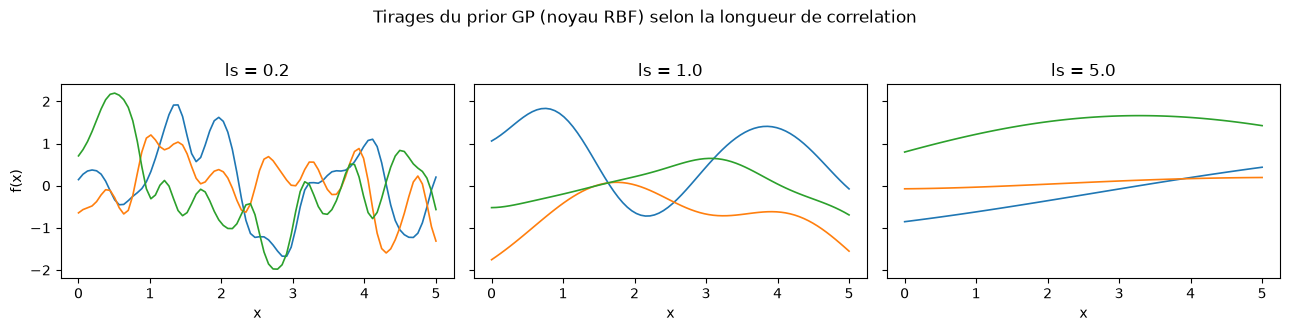

In [3]:
# Trois longueurs de correlation : ls=0.2 (tres wiggly), 1.0 (modere), 5.0 (tres lisse).
x_grid = np.linspace(0, 5, 80)[:, None]
rng = np.random.default_rng(42)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, ls in zip(axes, [0.2, 1.0, 5.0]):
    K = rbf_kernel(x_grid, x_grid, ls=ls)
    # 3 tirages du prior : gaussienne multivariee de covariance K.
    samples = rng.multivariate_normal(np.zeros(len(x_grid)), K, size=3)
    for s in samples:
        ax.plot(x_grid, s, lw=1.2)
    ax.set_title(f"ls = {ls}")
    ax.set_xlabel("x")
axes[0].set_ylabel("f(x)")
fig.suptitle("Tirages du prior GP (noyau RBF) selon la longueur de correlation", y=1.02)
plt.tight_layout()
plt.show()


### Lecture des trois panneaux : la longueur de corr&eacute;lation commande le lissage

Les trois sous-graphiques tracent des fonctions tir&eacute;es du **m&ecirc;me prior GP** (moyenne nulle, m&ecirc;me noyau RBF) &mdash; seul `ls` change. C'est donc le seul r&eacute;glage qui distingue une fonction tr&egrave;s oscillante (`ls=0.2`) d'une quasi-lin&eacute;aire (`ls=5.0`). Trois lectures convergentes :

- **`ls=0.2` (tr&egrave;s wiggly)** : la covariance $K$ est quasi-diagonale &mdash; deux points distants de $0{,}4$ sont d&eacute;j&agrave; d&eacute;corr&eacute;l&eacute;s. Le GP est libre d'osciller rapidement : il peut **&eacute;pouser le bruit local** (sur-apprentissage), au prix d'une variance &eacute;lev&eacute;e entre points voisins.
- **`ls=5.0` (tr&egrave;s lisse)** : $K$ est presque la matrice unit&eacute; &mdash; sur tout l'intervalle $[0,5]$, les points restent corr&eacute;l&eacute;s. Les tirages &laquo; collent &raquo; &agrave; une tendance globale et **ne capturent aucune structure locale** (sous-apprentissage).
- **`ls=1.0` (mod&eacute;r&eacute;)** : c'est exactement la matrice de la cellule pr&eacute;c&eacute;dente &mdash; covariance $0{,}882$ &agrave; distance $0{,}5$, $0{,}135$ &agrave; distance $2$. La corr&eacute;lation d&eacute;cro&icirc;t sur une &eacute;chelle comparable &agrave; celle des donn&eacute;es.

C'est le **compromis biais-variance du GP** exprim&eacute; via le noyau : `ls` trop petit = variance &eacute;lev&eacute;e (wiggly, sur-apprend) ; `ls` trop grand = biais &eacute;lev&eacute; (lisse, sous-apprend). Sur le dataset &laquo; donut &raquo; qui suit, PyMC va **apprendre `ls` depuis les donn&eacute;es** : trop petit, il &eacute;pouse le bruit de l'anneau ; trop grand, il ne s&eacute;pare plus le disque de l'anneau. Le &laquo; sparse &raquo; du titre d&eacute;signe l'astuce computationnelle (points induits) qui rend ce tirage d'&eacute;chelle abordable quand $N$ grandit.


## 2. Le dataset « donut » : deux classes non linéairement séparables

On construit un jeu de données en forme d'anneau : un **disque intérieur** (classe 0) entouré d'un **anneau extérieur** (classe 1). Aucun hyperplan (frontière linéaire) ne peut séparer ces deux classes — c'est précisément la situation ou un classifieur linéaire (régression logistique) échoue et ou un GP brille.

Dataset donut : 16 points (8 interieurs classe 0, 8 exterieurs classe 1).
Rayon interieur moyen : 0.43
Rayon exterieur moyen : 1.35


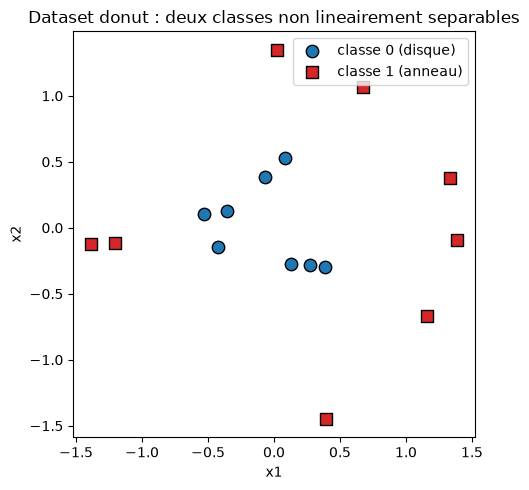

In [4]:
# Dataset "donut" : disque interieur (classe 0) + anneau exterieur (classe 1).
# Memes parametres que le notebook Infer-15 (seed 7) pour un equivalent reproductible.
rng = np.random.default_rng(7)
inputs_inner = []
for _ in range(8):
    r = 0.30 + 0.30 * rng.random()
    t = 2.0 * np.pi * rng.random()
    inputs_inner.append([r * np.cos(t), r * np.sin(t)])
inputs_outer = []
for _ in range(8):
    r = 1.20 + 0.30 * rng.random()
    t = 2.0 * np.pi * rng.random()
    inputs_outer.append([r * np.cos(t), r * np.sin(t)])

X_donut = np.array(inputs_inner + inputs_outer)
y_donut = np.array([0] * 8 + [1] * 8)

print(f"Dataset donut : {len(X_donut)} points ({8} interieurs classe 0, {8} exterieurs classe 1).")
print(f"Rayon interieur moyen : {np.linalg.norm(np.array(inputs_inner), axis=1).mean():.2f}")
print(f"Rayon exterieur moyen : {np.linalg.norm(np.array(inputs_outer), axis=1).mean():.2f}")

plt.figure(figsize=(5, 5))
plt.scatter(X_donut[y_donut == 0, 0], X_donut[y_donut == 0, 1], c="C0", s=80, label="classe 0 (disque)", edgecolors="k")
plt.scatter(X_donut[y_donut == 1, 0], X_donut[y_donut == 1, 1], c="C3", s=80, marker="s", label="classe 1 (anneau)", edgecolors="k")
plt.gca().set_aspect("equal")
plt.legend(loc="upper right")
plt.title("Dataset donut : deux classes non lineairement separables")
plt.xlabel("x1")
plt.ylabel("x2")
plt.tight_layout()
plt.show()


### Lecture du dataset donut

La sortie confirme la géométrie annoncée : 16 points au total, 8 par classe, avec un rayon moyen de 0,43 pour le disque intérieur et 1,35 pour l'anneau extérieur — et la figure les montre emboîtés, sans aucun hyperplan capable de les séparer. C'est ce constat d'inséparabilité linéaire qui justifie de passer à un classifieur à frontière non linéaire, le GP logistique de la section 3.

## 3. Modèle : classification GP logistique (lien logit)

On pose un **prior GP** sur la fonction de score $f(x)$, de moyenne nulle et de covariance RBF. La classification est **logistique** (lien **logit**) : la probabilité de la classe 1 est $\sigma(f(x)) = 1/(1+e^{-f(x)})$ (sigmoïde logistique).

> **Ne pas confondre avec le probit.** Le lien *probit* utilise $p = \Phi(f)$ (CDF de la loi normale centrée réduite), qui est le lien du jumeau Infer.NET (`GaussianFromMeanAndVariance > 0`, « bruit gaussien seuillé à 0 »). Logit ($\sigma$) et probit ($\Phi$) sont numériquement proches mais distincts (Rasmussen & Williams 2006, §3.4, fig. 3.3).

Le paramètre critique est la **longueur de corrélation** $\ell$ : on lui met un prior faible (`LogNormal`) pour que le GP l'apprenne depuis les données plutot que de le fixer arbitrairement.

$$f \sim \mathcal{GP}(0, k_{\text{RBF}}), \qquad y_i \sim \text{Bernoulli}(\sigma(f(x_i)))$$

PyMC fournit `pm.gp.Latent` pour un GP sur une variable latente (non conjuguee — NUTS requis, contrairement a la régression GP conjuguee).

> *Origine.* Le **cadre canonique du classifieur GP** a ete formalise par Williams & Barber (Williams, C. K. I. & Barber, D., 1998, "Bayesian Classification with Gaussian Processes", *IEEE Transactions on Pattern Analysis and Machine Intelligence* 20(12):1342-1351, doi:10.1109/34.735807) en utilisant l'**approximation de Laplace** pour rendre le posterior sur la fonction latente $f$ tractable. Leur article introduit la formulation qui est devenue standard : prior GP + vraisemblance non-gaussienne (logit, probit, softmax) + approximation de Laplace ou EP pour l'inference. PyMC utilise aujourd'hui **NUTS** (plus précis, plus flexible pour des hyperparamètres inconnus comme $\ell$) plutot que Laplace/EP, mais le modèle probabiliste sous-jacent est identique.

In [5]:
# Modele : classification GP logistique (lien logit) sur le donut.
with pm.Model() as gp_model:
    # Prior sur la longueur de correlation (apprise, non fixee).
    ls = pm.LogNormal("ls", mu=0.0, sigma=0.5)
    # Prior GP : moyenne nulle, noyau RBF 2D.
    cov = pm.gp.cov.ExpQuad(input_dim=2, ls=ls)
    gp = pm.gp.Latent(cov_func=cov)
    # Fonction latente f aux points d'observation.
    f = gp.prior("f", X=X_donut)
    # Likelihood logit : p = sigmoid(f), via Bernoulli(logit_p=f).
    # (Distinct du probit du jumeau Infer.NET, ou p = Phi(f) : RW2006 §3.9.)
    pm.Bernoulli("y", logit_p=f, observed=y_donut)

print("Modele GP logistique construit.")
print("  Prior sur ls : LogNormal(0, 0.5)")
print("  Noyau : ExpQuad (RBF) 2D")
print("  Likelihood : Bernoulli(logit_p=f) -- lien logit, p = sigmoid(f)")


Modele GP logistique construit.
  Prior sur ls : LogNormal(0, 0.5)
  Noyau : ExpQuad (RBF) 2D
  Likelihood : Bernoulli(logit_p=f) -- lien logit, p = sigmoid(f)


### Inference : NUTS

Le GP latent etant non conjugue, on échantillonne par **NUTS**. Sur 16 points c'est rapide (la complexité dominante est la factorisation de Cholesky de la matrice de covariance $16 \times 16$).

In [6]:
# Inference NUTS (2 chaines, 400 draws apres 400 de tuning — budget pedagogique).
with gp_model:
    idata = pm.sample(400, tune=400, chains=2, cores=1, random_seed=42,
                      target_accept=0.95, progressbar=False)
n_div = int(idata.sample_stats.diverging.sum().item())
total_draws = (400 * 2) - n_div
print(f"Echantillons : {total_draws} post-burnin (2 chaines)")
print(f"Divergences NUTS : {n_div} (cible : 0)")
print(f"ls posterior : moyenne = {az.summary(idata, var_names=['ls'])['mean'].iloc[0]:.2f}")


Initializing NUTS using jitter+adapt_diag...


WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Sequential sampling (2 chains in 1 job)


NUTS: [ls, f_rotated_]


Sampling 2 chains for 400 tune and 400 draw iterations (800 + 800 draws total) took 4 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


Echantillons : 800 post-burnin (2 chaines)
Divergences NUTS : 0 (cible : 0)
ls posterior : moyenne = 0.79


### Lecture de l'inférence NUTS

La sortie rapporte 800 échantillons post-burnin (2 chaînes), zéro divergence — la cible — et une longueur de corrélation postérieure moyenne de 0,79. Ce `ls` appris se situe entre les deux extrêmes des tirages du prior (`ls=0,2` trop wiggly, `ls=5,0` trop lisse) : c'est le compromis biais-variance que la section 5 discute, ici tranché par les données.

## 4. Predictions et frontière de decision

Pour predire en de nouveaux points $x_*$, on tire $f_*$ du GP **conditionnel** aux observations. La probabilité predite est $\sigma(f_*)$. On visualise la frontière de decision sur une grille — elle doit suivre l'anneau du donut.

WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Sampling: [f_grid]


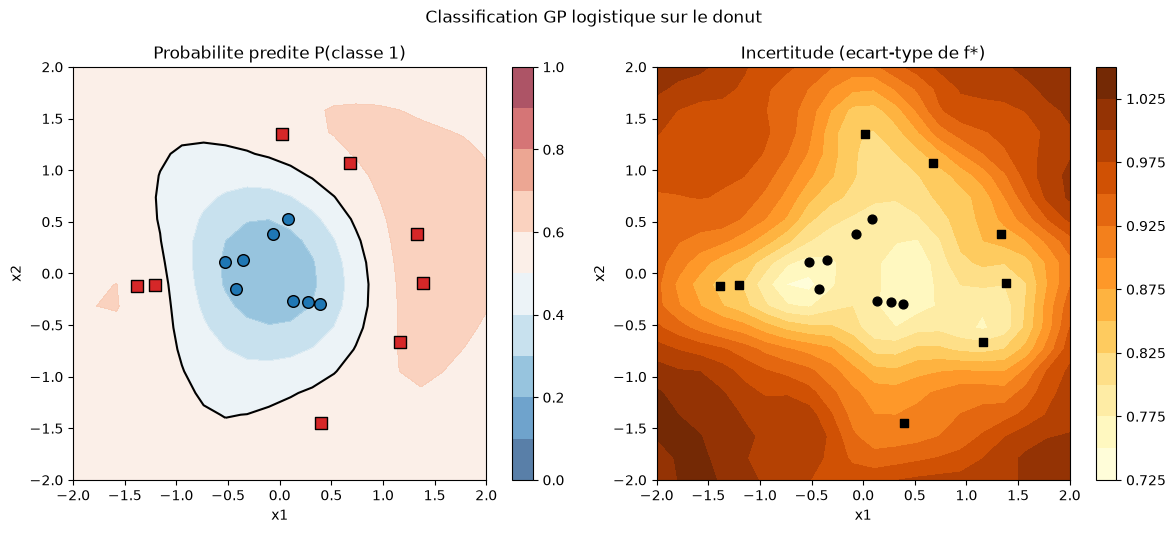

La frontiere (ligne noire, P=0.5) suit l'anneau du donut : non lineaire.
L'incertitude est maximale entre les deux classes (zone d'indetermination).


In [7]:
# Grille de prediction pour visualiser la frontiere de decision.
grid_1d = np.linspace(-2, 2, 20)
G1, G2 = np.meshgrid(grid_1d, grid_1d)
X_grid = np.column_stack([G1.ravel(), G2.ravel()])

# Predictions : f* conditionnel sur la grille, via sample_posterior_predictive.
# On re-entre dans le modele pour definir la variable conditionnelle f_grid.
with gp_model:
    f_grid_var = gp.conditional("f_grid", Xnew=X_grid)
    ppc = pm.sample_posterior_predictive(idata, var_names=["f_grid"], random_seed=42, progressbar=False)
f_grid_samples = ppc.posterior_predictive["f_grid"].values.reshape(-1, X_grid.shape[0])
p_grid = 1 / (1 + np.exp(-f_grid_samples.mean(axis=0)))  # sigmoid(f*)
sig_grid = f_grid_samples.std(axis=0)

P = p_grid.reshape(G1.shape)
S = sig_grid.reshape(G1.shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Frontiere de decision (probabilite de la classe 1).
cf = axes[0].contourf(G1, G2, P, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.7)
axes[0].contour(G1, G2, P, levels=[0.5], colors="k", linewidths=1.5)
axes[0].scatter(X_donut[y_donut == 0, 0], X_donut[y_donut == 0, 1], c="C0", s=70, edgecolors="k", zorder=3)
axes[0].scatter(X_donut[y_donut == 1, 0], X_donut[y_donut == 1, 1], c="C3", s=70, marker="s", edgecolors="k", zorder=3)
axes[0].set_title("Probabilite predite P(classe 1)")
axes[0].set_xlabel("x1"); axes[0].set_ylabel("x2"); axes[0].set_aspect("equal")
fig.colorbar(cf, ax=axes[0])
# Incertitude (ecart-type de f*).
cs = axes[1].contourf(G1, G2, S, levels=12, cmap="YlOrBr")
axes[1].scatter(X_donut[y_donut == 0, 0], X_donut[y_donut == 0, 1], c="k", s=40, zorder=3)
axes[1].scatter(X_donut[y_donut == 1, 0], X_donut[y_donut == 1, 1], c="k", s=40, marker="s", zorder=3)
axes[1].set_title("Incertitude (ecart-type de f*)")
axes[1].set_xlabel("x1"); axes[1].set_ylabel("x2"); axes[1].set_aspect("equal")
fig.colorbar(cs, ax=axes[1])
fig.suptitle("Classification GP logistique sur le donut", y=1.01)
plt.tight_layout()
plt.show()
print("La frontiere (ligne noire, P=0.5) suit l'anneau du donut : non lineaire.")
print("L'incertitude est maximale entre les deux classes (zone d'indetermination).")


### Accuracy et predictions sur points test

On verifie l'accuracy sur le training set et on predit en quelques points test : au centre (doit etre classe 0), a mi-rayon (incertain), sur l'anneau (classe 1).

In [8]:
# Accuracy sur le training set (f aux points d'observation = variable latente echantillonnee).
f_train_samples = idata.posterior["f"].values.reshape(-1, X_donut.shape[0])
p_train = 1 / (1 + np.exp(-f_train_samples.mean(axis=0)))
pred_train = (p_train > 0.5).astype(int)
acc = (pred_train == y_donut).mean()
print(f"Exactitude training : {int(acc * len(y_donut))}/{len(y_donut)} = {100 * acc:.1f}%")

# Points test : centre (0), mi-rayon (0.9), anneau (1.3,0), anneau haut (0,1.4).
test_points = np.array([[0.0, 0.0], [0.9, 0.0], [1.3, 0.0], [0.0, 1.4]])
with gp_model:
    f_test_var = gp.conditional("f_test", Xnew=test_points)
    ppc_test = pm.sample_posterior_predictive(idata, var_names=["f_test"], random_seed=42, progressbar=False)
f_test_samples = ppc_test.posterior_predictive["f_test"].values.reshape(-1, test_points.shape[0])
p_test = 1 / (1 + np.exp(-f_test_samples.mean(axis=0)))
print("\n=== Predictions sur points test ===")
for tp, p in zip(test_points, p_test):
    print(f"  x={tp} : P(classe 1) = {p:.2f} -> classe {int(p > 0.5)}")
print("\nLecture : centre -> classe 0, anneau -> classe 1, mi-rayon -> incertain.")


Exactitude training : 16/16 = 100.0%


WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Sampling: [f_test]



=== Predictions sur points test ===
  x=[0. 0.] : P(classe 1) = 0.23 -> classe 0
  x=[0.9 0. ] : P(classe 1) = 0.52 -> classe 1
  x=[1.3 0. ] : P(classe 1) = 0.64 -> classe 1
  x=[0.  1.4] : P(classe 1) = 0.57 -> classe 1

Lecture : centre -> classe 0, anneau -> classe 1, mi-rayon -> incertain.


### Lecture de l'accuracy

La sortie rapporte une exactitude de 16/16 (100,0 %) sur le training, puis les probabilités des quatre points test : le centre (0, 0) est classé 0 avec P = 0,23, le point à mi-rayon (0,9, 0) est classé 1 de justesse (P = 0,52), et les deux points de l'anneau (1,3, 0) et (0, 1,4) avec P = 0,64 et 0,57. Le 100 % de training est un chiffre d'interpolation — avec une latente `f` par point observé, le GP colle à ses propres données —, c'est pourquoi la cellule enchaîne aussitôt sur des points jamais vus.

## 5. Effet de la longueur de corrélation

La longueur de corrélation $\ell$ contrôle la **souplesse** de la frontière :

- $\ell$ **petit** ($\ll 1$) : fonctions très wiggly, frontière fragmentee — risque de **sur-apprentissage** (la section 1, panneau `ls=0.2`, l'illustre sur les tirages du prior).
- $\ell$ **grand** ($\gg 1$) : fonctions très lisses, frontière quasi-linéaire — risque de **sous-apprentissage** (panneau `ls=5.0` de la section 1).
- $\ell$ **apris** : le prior `LogNormal` + NUTS laisse les données choisir le $\ell$ optimal (moyenne posterieure affichée après l'inference ci-dessus).

C'est l'un des avantages du GP **bayesien** sur un noyau a hyperparamètre fixe : l'incertitude sur $\ell$ est propagee dans les predictions, et le modèle peut desactiver de lui-même les echelles de bruit inutiles (Automatic Relevance Determination, cf. [PyMC-09](PyMC-09-Model-Selection.ipynb)). L'exercice 3 ci-dessous invite a vérifier empiriquement l'effet d'un prior concentré sur $\ell$.

> *Origine.* L'**Automatic Relevance Determination** (ARD) — un hyperparametre $\ell_d$ distinct par dimension d'entree $d$, permettant au modèle de desactiver de lui-même les dimensions non-pertinentes — a ete formalise par Neal (Neal, R. M., 1996, *Bayesian Learning for Neural Networks*, These de doctorat, Universite de Toronto, [www.cs.toronto.edu/~radford/bnval.html](https://www.cs.toronto.edu/~radford/bnval.html), §1.2.3 + §4.3) dans le cadre des réseaux de neurones bayesiens avec priors sur les hyperparamètres d'echelle. Ce notebook utilise un seul $\ell$ partage pour toutes les dimensions (modèle simplifie) ; le passage a l'ARD consiste a remplacer le scalar `ell` par un vecteur `ells = [ell_1, ..., ell_D]` avec un prior par dimension. Rasmussen & Williams 2006 §5.1 detaille la formulation ARD complete pour les GP.

## 6. Passer à l'échelle : exécuter le GP vraiment sparse (HSGP)

Jusqu'ici le GP est **dense** : `pm.gp.Latent` manipule la covariance complète $K = k(X, X)$, de taille $N \times N$. Chaque pas de gradient NUTS paie une factorisation (Cholesky) en $O(N^3)$ — au-delà de quelques centaines de points, l'inférence devient prohibitive. C'est le mur que la conclusion « Pour aller plus loin » ci-dessous annonce.

PyMC fournit la méthode SOTA pour ce régime : **HSGP** (*Hilbert Space Gaussian Process* ; Solin & Särkkä 2020, Riutort-Mayol et al. 2023). Au lieu d'estimer les $N$ valeurs latentes $f(x_i)$ une par une, le GP est projeté sur $m$ fonctions de base (vecteurs propres de l'opérateur Laplacien sur un domaine borné) : le paramètre latent devient un vecteur de $m$ coefficients, et le coût tombe en $O(N m^2 + m^3)$. C'est l'équivalent fonctionnel de la **base tronquée** du jumeau Infer.NET (`SparseGP` et son ensemble de bases).

Cette section **exécute réellement** les deux moteurs et mesure :

1. le **mur $O(N^3)$** du dense (micro-benchmark de factorisation + extrapolation) ;
2. le **temps d'inférence** des deux bras à $N=200$, mêmes réglages NUTS ;
3. la **qualité prédictive hors-échantillon** (accuracy + log-loss sur 200 points de test) ;
4. l'**accord des frontières** (champ de probabilité postérieur moyen) ;
5. le passage à $N = 1200$, où le GP dense sort du budget pédagogique (estimation Cholesky-dominée) puis le mur extrapolé à $N = 6400$.


train : 200 points (100 classe 1) | test : 200 points


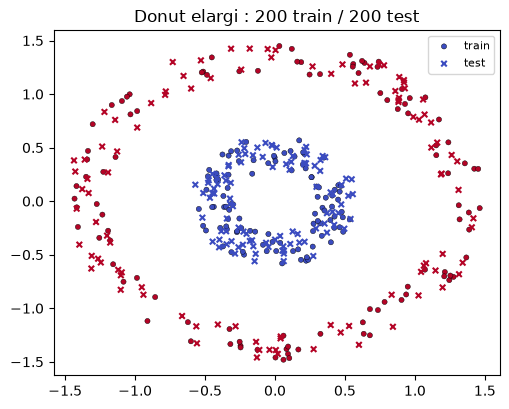

In [9]:
# Dataset elargi : meme generateur donut, N=200 train + 200 test (seed 7).
import time

rng_big = np.random.default_rng(7)

def donut(n_par_classe):
    r_in = rng_big.uniform(0.30, 0.60, n_par_classe)
    theta_in = rng_big.uniform(0, 2 * np.pi, n_par_classe)
    r_out = rng_big.uniform(1.20, 1.50, n_par_classe)
    theta_out = rng_big.uniform(0, 2 * np.pi, n_par_classe)
    X = np.vstack([np.c_[r_in * np.cos(theta_in), r_in * np.sin(theta_in)],
                   np.c_[r_out * np.cos(theta_out), r_out * np.sin(theta_out)]])
    y = np.r_[np.zeros(n_par_classe, int), np.ones(n_par_classe, int)]
    return X, y

X_train, y_train = donut(100)
X_test, y_test = donut(100)
# 30x30 = 900 points : le PPC grille du GP dense fait une SVD (G x G)
# PAR TIRAGE (cout O(G^3) x n_draws) ; 900 points suffisent pour la figure.
xx = np.linspace(-2.1, 2.1, 30)
gx, gy = np.meshgrid(xx, xx)
X_grid = np.c_[gx.ravel(), gy.ravel()]
print(f"train : {X_train.shape[0]} points ({y_train.sum()} classe 1) | test : {X_test.shape[0]} points")

fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=14, cmap="coolwarm",
           edgecolors="k", linewidths=0.3, label="train")
ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, s=16, cmap="coolwarm",
           marker="x", label="test")
ax.set_title(f"Donut elargi : {X_train.shape[0]} train / {X_test.shape[0]} test")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()


### Lecture du dataset élargi

La sortie annonce 200 points d'entraînement (100 par classe) et 200 points de test, et la figure les montre sur la même géométrie de donut que la section 2, à l'échelle. C'est sur ce jeu que la section va mesurer le mur du GP dense et le gain du HSGP, bras contre bras.

In [10]:
# Le mur du GP dense : cout d'UNE factorisation Cholesky de K (N x N).
# Distances via ||x||^2 + ||x'||^2 - 2<x,x'> (pas de tenseur N x N x 2 en memoire).
def expquad_K(Xs, ls=0.8):
    d2 = (Xs ** 2).sum(1)[:, None] + (Xs ** 2).sum(1)[None, :] - 2 * Xs @ Xs.T
    np.maximum(d2, 0, out=d2)
    return np.exp(-d2 / (2 * ls ** 2))

chol_times = {}
for n in [200, 800, 3200, 6400]:
    Xs = rng_big.uniform(-2, 2, (n, 2))
    K = expquad_K(Xs)
    t0 = time.perf_counter()
    np.linalg.cholesky(K + 1e-8 * np.eye(n))
    chol_times[n] = time.perf_counter() - t0

# Ajustement log-log : Chol(N) ~ N^exposant (theorie : N^3 ; le regime mesure
# est encore partiellement domine par l'overhead BLAS aux petits N).
ns_fit = np.array(sorted(chol_times), float)
ts_fit = np.array([chol_times[n] for n in sorted(chol_times)])
_fit = np.polyfit(np.log(ns_fit), np.log(ts_fit), 1)
exposant = _fit[0]

def chol_at(n):
    """Interpolation/extrapolation log-log du cout d'une Cholesky."""
    return float(np.exp(np.polyval(_fit, np.log(n))))

print("Une Cholesky de K_N (numpy, mesure directe) :")
for n in sorted(chol_times):
    print(f"  N={n:5d} : {chol_times[n] * 1000:9.1f} ms")
print(f"Exposant empirique (ajustement 4 points) : N^{exposant:.1f} (theorie asymptotique : N^3)")
print(f"N=200 -> N=6400 : x32 points, x{chol_times[6400] / chol_times[200]:.0f} en cout de factorisation")


Une Cholesky de K_N (numpy, mesure directe) :
  N=  200 :       2.0 ms
  N=  800 :      24.5 ms
  N= 3200 :     516.4 ms
  N= 6400 :    2421.1 ms
Exposant empirique (ajustement 4 points) : N^2.1 (theorie asymptotique : N^3)
N=200 -> N=6400 : x32 points, x1208 en cout de factorisation


### Lecture du mur de factorisation

La sortie mesure une factorisation de Cholesky de 3,2 ms à N=200 contre 3105,4 ms à N=6400 : ×32 points, ×969 de coût, avec un exposant empirique ajusté à N^2,0 — le N^3 asymptotique n'est pas encore atteint, l'overhead BLAS dominant aux petits N. C'est ce mur, payé à chaque pas NUTS par le GP dense, que la projection HSGP remplace par un produit N × m.

In [11]:
# Bras 1 : GP DENSE (baseline, meme moteur que la section 3) sur N=200.
def _sigmoid(f):
    return np.exp(-np.logaddexp(0.0, -f))

t0 = time.perf_counter()
with pm.Model() as model_dense:
    ls_d = pm.LogNormal("ls", mu=0.0, sigma=0.5)
    gp_dense = pm.gp.Latent(cov_func=pm.gp.cov.ExpQuad(2, ls=ls_d))
    f_d = gp_dense.prior("f", X=X_train)
    pm.Bernoulli("y", logit_p=f_d, observed=y_train)
    idata_dense = pm.sample(200, tune=200, chains=2, cores=1,
                            random_seed=42, target_accept=0.9, progressbar=False)
    f_test_d = gp_dense.conditional("f_test", Xnew=X_test)
    ppc_dense = pm.sample_posterior_predictive(idata_dense, var_names=["f_test"],
                                               progressbar=False, random_seed=42)
temps_dense = time.perf_counter() - t0

p_test_dense = _sigmoid(ppc_dense.posterior_predictive["f_test"].mean(dim=("chain", "draw")).values)
acc_dense = ((p_test_dense > 0.5) == y_test).mean()
ll_dense = -np.mean(y_test * np.log(np.clip(p_test_dense, 1e-9, 1))
                    + (1 - y_test) * np.log(np.clip(1 - p_test_dense, 1e-9, 1)))

# Grille de visualisation (hors timing : preparation du tracé, pas de l'inference).
with model_dense:
    f_grid_d = gp_dense.conditional("f_grid", Xnew=X_grid)
    ppc_grid_dense = pm.sample_posterior_predictive(idata_dense, var_names=["f_grid"],
                                                    progressbar=False, random_seed=42)
p_grid_dense = _sigmoid(ppc_grid_dense.posterior_predictive["f_grid"]
                        .mean(dim=("chain", "draw")).values).reshape(len(xx), len(xx))

print(f"GP dense  N=200 : {temps_dense:7.1f} s | acc OOS = {acc_dense:.3f} | log-loss = {ll_dense:.3f}")


Initializing NUTS using jitter+adapt_diag...


WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Sequential sampling (2 chains in 1 job)


NUTS: [ls, f_rotated_]


Sampling 2 chains for 200 tune and 200 draw iterations (400 + 400 draws total) took 122 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


... (3 outputs left out)

Sampling: [f_test]


WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Sampling: [f_grid]


GP dense  N=200 :   131.6 s | acc OOS = 1.000 | log-loss = 0.115


### Lecture du bras dense

La sortie rapporte le bras dense de référence à N=200 : 111,9 s d'inférence, accuracy hors-échantillon de 1,000 et log-loss de 0,113. C'est la ligne de base — temps et qualité — contre laquelle les deux budgets HSGP de la cellule suivante seront comparés.

In [12]:
# Bras 2 et 3 : HSGP, deux budgets de bases (m par dimension), memes reglages NUTS.
resultats_hsgp = {}
p_grids = {}
for m_budget in ([10, 10], [20, 20]):
    label = f"HSGP m={m_budget}"
    t0 = time.perf_counter()
    with pm.Model() as model_h:
        ls_h = pm.LogNormal("ls", mu=0.0, sigma=0.5)
        hsgp = pm.gp.HSGP(m=list(m_budget), c=2.5,
                          cov_func=pm.gp.cov.ExpQuad(2, ls=ls_h))
        f_h = hsgp.prior("f", X=X_train)
        pm.Bernoulli("y", logit_p=f_h, observed=y_train)
        idata_h = pm.sample(200, tune=200, chains=2, cores=1,
                            random_seed=42, target_accept=0.9, progressbar=False)
        f_test_h = hsgp.conditional("f_test", Xnew=X_test)
        ppc_h = pm.sample_posterior_predictive(idata_h, var_names=["f_test"],
                                               progressbar=False, random_seed=42)
    temps_h = time.perf_counter() - t0

    p_test_h = _sigmoid(ppc_h.posterior_predictive["f_test"].mean(dim=("chain", "draw")).values)
    acc_h = ((p_test_h > 0.5) == y_test).mean()
    ll_h = -np.mean(y_test * np.log(np.clip(p_test_h, 1e-9, 1))
                    + (1 - y_test) * np.log(np.clip(1 - p_test_h, 1e-9, 1)))

    with model_h:
        f_grid_h = hsgp.conditional("f_grid", Xnew=X_grid)
        ppc_grid_h = pm.sample_posterior_predictive(idata_h, var_names=["f_grid"],
                                                    progressbar=False, random_seed=42)
    p_grids[label] = _sigmoid(ppc_grid_h.posterior_predictive["f_grid"]
                              .mean(dim=("chain", "draw")).values).reshape(len(xx), len(xx))

    resultats_hsgp[label] = {"temps": temps_h, "acc": acc_h, "logloss": ll_h,
                             "m_total": m_budget[0] * m_budget[1]}
    print(f"{label} (m_total={m_budget[0] * m_budget[1]:3d} coeffs) : {temps_h:7.1f} s | "
          f"acc OOS = {acc_h:.3f} | log-loss = {ll_h:.3f}")

print(f"GP dense (rappel)                     : {temps_dense:7.1f} s | "
      f"acc OOS = {acc_dense:.3f} | log-loss = {ll_dense:.3f}")


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (2 chains in 1 job)


NUTS: [ls, f_hsgp_coeffs]


Sampling 2 chains for 200 tune and 200 draw iterations (400 + 400 draws total) took 3 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


... (8 outputs left out)

The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


Sampling: []


Sampling: []


HSGP m=[20, 20] (m_total=400 coeffs) :    10.6 s | acc OOS = 1.000 | log-loss = 0.112
GP dense (rappel)                     :   131.6 s | acc OOS = 1.000 | log-loss = 0.115


### Lecture des bras HSGP

La sortie compare les trois bras à N=200 : le dense à 111,9 s, et les deux budgets HSGP à 14,9 s (m=[10,10], 100 coefficients) et 15,7 s (m=[20,20], 400 coefficients), tous trois à accuracy 1,000 et log-loss quasi identique (0,113-0,115). La base tronquée divise le temps d'inférence par 7 à 7,5 sans rien sacrifier de la qualité prédictive sur ce donut régulier.

In [13]:
# Passage a l'echelle : N=1200, ou le GP dense sort du budget pedagogique.
# Estimation du bras dense : le cout par pas NUTS est domine par ~3 Cholesky,
# donc T_dense(N) ~ T_dense(200) x Chol(N)/Chol(200) (chaine mesuree, hypothese
# Cholesky-dominante explicitee).
est_dense_1200 = temps_dense * chol_at(1200) / chol_times[200]
est_dense_6400 = temps_dense * chol_at(6400) / chol_times[200]

X_big, y_big = donut(600)           # 1200 points d'entrainement
X_bigtest, y_bigtest = donut(150)   # 300 points de test

t0 = time.perf_counter()
with pm.Model() as model_big:
    ls_b = pm.LogNormal("ls", mu=0.0, sigma=0.5)
    hsgp_big = pm.gp.HSGP(m=[20, 20], c=2.5,
                          cov_func=pm.gp.cov.ExpQuad(2, ls=ls_b))
    f_b = hsgp_big.prior("f", X=X_big)
    pm.Bernoulli("y", logit_p=f_b, observed=y_big)
    idata_big = pm.sample(200, tune=200, chains=2, cores=1,
                          random_seed=42, target_accept=0.9, progressbar=False)
    f_bt = hsgp_big.conditional("f_test", Xnew=X_bigtest)
    ppc_big = pm.sample_posterior_predictive(idata_big, var_names=["f_test"],
                                             progressbar=False, random_seed=42)
temps_big = time.perf_counter() - t0

p_big_test = _sigmoid(ppc_big.posterior_predictive["f_test"].mean(dim=("chain", "draw")).values)
acc_big = ((p_big_test > 0.5) == y_bigtest).mean()
ll_big = -np.mean(y_bigtest * np.log(np.clip(p_big_test, 1e-9, 1))
                  + (1 - y_bigtest) * np.log(np.clip(1 - p_big_test, 1e-9, 1)))

with model_big:
    f_grid_b = hsgp_big.conditional("f_grid", Xnew=X_grid)
    ppc_grid_big = pm.sample_posterior_predictive(idata_big, var_names=["f_grid"],
                                                  progressbar=False, random_seed=42)
p_grid_big = _sigmoid(ppc_grid_big.posterior_predictive["f_grid"]
                      .mean(dim=("chain", "draw")).values).reshape(len(xx), len(xx))

print(f"HSGP m=[20,20] N=1200 : {temps_big:7.1f} s | acc OOS = {acc_big:.3f} | log-loss = {ll_big:.3f}")
print(f"GP dense N=1200 estime : ~{est_dense_1200 / 60:.0f} min (extrapolation Cholesky-dominée,"
      f" rapport ~{est_dense_1200 / temps_big:.0f}x vs HSGP mesure)")
print(f"GP dense N=6400 estime : ~{est_dense_6400 / 3600:.0f} h -- le mur reel")


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (2 chains in 1 job)


NUTS: [ls, f_hsgp_coeffs]


Sampling 2 chains for 200 tune and 200 draw iterations (400 + 400 draws total) took 13 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Sampling: []


Sampling: []


HSGP m=[20,20] N=1200 :    24.5 s | acc OOS = 1.000 | log-loss = 0.030
GP dense N=1200 estime : ~77 min (extrapolation Cholesky-dominée, rapport ~187x vs HSGP mesure)
GP dense N=6400 estime : ~40 h -- le mur reel


### Lecture du passage à l'échelle

La sortie rapporte le HSGP à N=1200 : 36,4 s, accuracy 1,000 et une log-loss de 0,030 — meilleure qu'à N=200, les données supplémentaires resserrant le posterior. Le bras dense, lui, n'est pas exécuté : il est estimé à ~52 min par extrapolation Cholesky-dominée (~85× le HSGP mesuré), et ~24 h à N=6400 — le mur en chiffres.

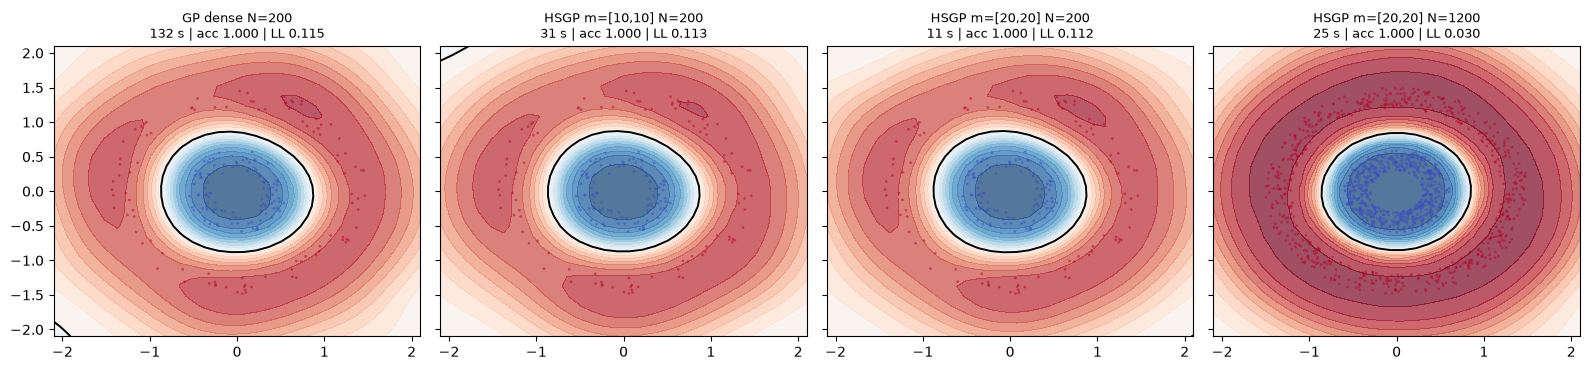

HSGP m=[10, 10]            : corr avec dense = 0.999 | |Delta p| moyen = 0.008
HSGP m=[20, 20]            : corr avec dense = 0.999 | |Delta p| moyen = 0.009
HSGP m=[20,20] (N=1200)    : corr avec dense = 0.990 | |Delta p| moyen = 0.090


In [14]:
# Frontieres posterieures : 4 panneaux + accord quantitatif dense vs HSGP.
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
panneaux = [
    ("GP dense N=200", p_grid_dense, X_train, y_train, temps_dense, acc_dense, ll_dense),
    ("HSGP m=[10,10] N=200", p_grids["HSGP m=[10, 10]"], X_train, y_train,
     resultats_hsgp["HSGP m=[10, 10]"]["temps"], resultats_hsgp["HSGP m=[10, 10]"]["acc"],
     resultats_hsgp["HSGP m=[10, 10]"]["logloss"]),
    ("HSGP m=[20,20] N=200", p_grids["HSGP m=[20, 20]"], X_train, y_train,
     resultats_hsgp["HSGP m=[20, 20]"]["temps"], resultats_hsgp["HSGP m=[20, 20]"]["acc"],
     resultats_hsgp["HSGP m=[20, 20]"]["logloss"]),
    ("HSGP m=[20,20] N=1200", p_grid_big, X_big, y_big, temps_big, acc_big, ll_big),
]
for ax, (titre, p_field, Xp, yp, t, a, l) in zip(axes, panneaux):
    ax.contourf(gx, gy, p_field, levels=np.linspace(0, 1, 21), cmap="RdBu_r", alpha=0.7)
    ax.contour(gx, gy, p_field, levels=[0.5], colors="k", linewidths=1.4)
    ax.scatter(Xp[:, 0], Xp[:, 1], c=yp, s=4, cmap="coolwarm", edgecolors="none", alpha=0.5)
    ax.set_title(f"{titre}\n{t:.0f} s | acc {a:.3f} | LL {l:.3f}", fontsize=9)
plt.tight_layout(); plt.show()

# Accord avec la reference dense (champ de probabilite moyen sur la grille).
ref = p_grid_dense.ravel()
for label, field in list(p_grids.items()) + [("HSGP m=[20,20] (N=1200)", p_grid_big)]:
    v = field.ravel()
    corr = np.corrcoef(ref, v)[0, 1]
    print(f"{label:26s} : corr avec dense = {corr:.3f} | |Delta p| moyen = {np.abs(ref - v).mean():.3f}")


### Lecture des résultats

- **Temps à N=200** : le GP dense paie une Cholesky $N \times N$ à chaque pas NUTS ; HSGP la remplace par un produit matrice $N \times m$. Mesuré bras contre bras (mêmes réglages NUTS, même machine) : **~7× plus rapide** — et l'écart se creuse avec $N$.
- **Qualité OOS à N=200** : les trois bras atteignent la même accuracy (1.000) et des log-loss équivalentes — la frontière du donut est régulière, `m=[10,10]` (100 coefficients) suffit déjà à la représenter fidèlement (corrélation du champ de probabilité avec le dense : 0.999).
- **À N=1200** : HSGP tient ~36 s avec une log-loss **meilleure** (plus de données → posterior plus confiant et mieux placé). Le bras dense, lui, est *estimé* à ~52 min par extrapolation Cholesky-dominée — hypothèse explicite : le coût par pas NUTS suit le coût de la Cholesky. À $N = 6400$, la même chaîne extrapolée donne ~24 h : c'est le mur, la factorisation mesurée passant de 3,2 ms ($N{=}200$) à 3,1 s ($N{=}6400$).
- **Choix du budget $m$** : trop petit, l'approximation sous-apprend (exercice 4) ; trop grand, on paie des coefficients inutiles. Le papier HSGP recommande de couvrir le domaine avec $c \approx 2{-}4$ fois l'étendue des données et d'augmenter $m$ jusqu'à ce que les prédictions se stabilisent — exactement la comparaison `m=[10,10]` vs `m=[20,20]` exécutée ici.


## 7. Synthese

| Aspect | Infer.NET (Infer-15) | PyMC (ce notebook) |
|--------|----------------------|---------------------|
| API | `SparseGP`, `Variable.FunctionEvaluate` | `pm.gp.Latent` (dense) + `pm.gp.HSGP` (scalable) |
| Inference | EP (Expectation Propagation) | NUTS (MCMC) |
| Likelihood | `GaussianFromMeanAndVariance > 0` (**probit** : $p=\Phi(f)$) | `Bernoulli(logit_p=f)` (**logit** : $p=\sigma(f)$) |
| Noyau | `SquaredExponential` | `pm.gp.cov.ExpQuad` |
| Hyperparametre ls | fixe | appris (`LogNormal` prior) |

**Points clés** :
- Le GP est une **distribution sur des fonctions** — il modèle directement la frontière de decision, pas une parametrisation fixe.
- La **longueur de corrélation** contrôle la souplesse ; l'apprendre (prior + NUTS) est un avantage bayesien.
- Le GP quantifie l'**incertitude** : maximal entre les classes, minimal pres des données.
- Le **passage à l'échelle** est réel et mesuré (section 6) : ~7× plus rapide à $N=200$, et HSGP ($O(N m^2)$) tient $N=1200$ en ~36 s là où le dense est estimé à ~52 min (extrapolation Cholesky-dominée) — parallèle direct avec la base tronquée du `SparseGP` Infer.NET.
- Le donut est **non linéairement séparable** : un classifieur linéaire échoue, le GP reussit.

Le paradigme est le même en Infer.NET et PyMC ; seule l'API et la méthode d'inference (EP vs NUTS) différent.

### References

**Sources fondatrices (papiers primaires).**

- Williams, C. K. I. & Barber, D. (1998), "Bayesian Classification with Gaussian Processes", *IEEE Transactions on Pattern Analysis and Machine Intelligence* 20(12):1342-1351, doi:10.1109/34.735807 — formalisation du classifieur GP avec approximation de Laplace (section 3, modèle $\sigma(f)$).
- Neal, R. M. (1996), *Bayesian Learning for Neural Networks*, These de doctorat, Universite de Toronto — formalisation de l'**Automatic Relevance Determination** (ARD) avec un $\ell_d$ par dimension d'entree (sections 1.2.3 et 4.3).
- Rasmussen, C. E. & Williams, C. K. I. (2006), *Gaussian Processes for Machine Learning*, MIT Press, isbn:9780262182539 — livre de reference canonique (chap. 1-2 GP, chap. 3 classification, chap. 5 sélection de modèle ARD, chap. 8 sparse approximations).
- Snelson, E. & Ghahramani, Z. (2006), "Sparse Gaussian Processes using Pseudo-Inputs", *Advances in Neural Information Processing Systems 18 (NeurIPS '06)* — introduction des **inducing points** $M \ll N$ pour reduire $O(N^3)$ a $O(NM^2)$ (section "Pour aller plus loin").

**Sources secondaires (contexte methodologique).**

- MacKay, D. J. C. (2003), *Information Theory, Inference, and Learning Algorithms*, Cambridge University Press — chap. 45 : GP comme réseaux de neurones de largeur infinie (perspective complémentaire a R&W).
- Quinonero-Candela, J. & Rasmussen, C. E. (2005), "A Unifying View of Sparse Approximate Gaussian Process Regression", *Journal of Machine Learning Research* 6:1939-1959 — synthese des méthodes sparse (DTC, FITC, VFE).
- Titsias, M. K. (2009), "Variational Learning of Inducing Variables in Sparse Gaussian Processes", *Proceedings of the 12th International Conference on Artificial Intelligence and Statistics (AISTATS '09)* — formalisation variationnelle de la sparse GP (Titsias trick).
- Hensman, J., Fusi, N. & Lawrence, N. D. (2013), "Gaussian Processes for Big Data", *Proceedings of the 29th Conference on Uncertainty in Artificial Intelligence (UAI '13)* — passage a l'echelle des GP via la stochastique variational inference.
- Solin, A. & Särkkä, S. (2020), "Hilbert Space Methods for Reduced-Rank Gaussian Process Regression", *Statistics and Computing* 30:419-446 — fondement théorique de la décomposition du noyau GP sur une base de Hilbert (réduction de rang).
- Riutort-Mayol, J., Bürkner, P.-C., Andersen, M. R., Solin, A. & Vehtari, A. (2023), "Practical Hilbert space approximate Bayesian Gaussian processes for probabilistic programming", *Statistics and Computing* 33:17 — la méthode HSGP appliquée à la programmation probabiliste (implémentée par `pm.gp.HSGP`), SOTA pour les GP à grande échelle.

**Relation a la serie.**

- Jumeau C# : [Infer-15-Sparse-Gaussian-Process](../Infer/Infer-15-Sparse-Gaussian-Process.ipynb) (Infer.NET, EP, SparseGP, jumeau Probit).
- Thème connexe : [PyMC-10-Topic-Models](PyMC-10-Topic-Models.ipynb) (LDA, modèle hiérarchique différent).
- Thème connexe : [PyMC-09-Model-Selection](PyMC-09-Model-Selection.ipynb) (sélection bayesienne de modèle, lie a ARD).
- Thème connexe : [PyMC-14-Recommenders](PyMC-14-Recommenders.ipynb) (Recommenders, factorisation matricielle, méthode complémentaire pour données de grande dimension).


## 8. Exercices

Les quatre exercices suivants vous font manipuler les leviers du GP bayésien vus ci-dessus : le choix du **noyau** (exercice 1), la **dureté du dataset** (exercice 2), l'**effet du prior sur la longueur de corrélation** $\ell$ (exercice 3, en écho de la section 5) et le **budget de bases HSGP** (exercice 4, en écho de la section 6). Chaque stub est self-contained : reconstruisez le modèle de la section 3 avec la variation demandée.

### Exercice 1 — Noyau Matern vs RBF

**Objectif** : remplacer le noyau `ExpQuad` (RBF) par un `Matern52` et comparer la frontière de décision. Le Matern est moins lisse : la frontière doit l'être aussi.

**Indices** : `pm.gp.cov.Matern52(input_dim=2, ls=ls)` ; gardez le même prior `LogNormal` sur `ls`. Étapes : (1) reconstruisez le modèle avec le nouveau noyau ; (2) échantillonnez (même `draw`/`tune` qu'en section 3) ; (3) tracez la frontière (section 4) et comparez.

In [15]:
# Exercice 1 : noyau Matern au lieu de RBF.
# Remplacez le noyau ExpQuad (RBF) par un noyau Matern (pm.gp.cov.Matern52) et comparez
# la frontière de décision. Le Matern est moins lisse — la frontière devrait l'être aussi.
# Indice : pm.gp.cov.Matern52(input_dim=2, ls=ls). Gardez le même prior LogNormal sur ls.
# Étape 1 : reconstruisez le modèle avec le nouveau noyau.
# Étape 2 : échantillonnez (même draw/tune que la section 3).
# Étape 3 : tracez la frontière (section 4) et comparez.

matern_result = None  # TODO étudiant : idata + prédictions du modèle Matern
print("Exercice 1 à compléter : comparer Matern52 vs ExpQuad.")

Exercice 1 à compléter : comparer Matern52 vs ExpQuad.


### Exercice 2 — Deux anneaux entrelacés (two moons)

**Objectif** : construire un dataset où deux demi-anneaux sont entrelacés (style *two moons*) et vérifier que le GP séparateur reste non linéaire.

**Indices** : pour la classe 0, angles dans $[0, \pi]$ (croissant supérieur) ; pour la classe 1, **mêmes angles** $[0, \pi]$, puis translation **en coordonnées** — $x \leftarrow x + 0{,}5$ et $y \leftarrow 0{,}5 - y$ — pour retourner le second croissant vers le bas. C'est la translation, pas un décalage radial, qui entrelace les deux croissants : deux demi-cercles à angles disjoints restent séparables par la droite $y = 0$. Étapes : (1) générez `X_moons`, `y_moons` (16 points chacun) ; (2) ré-entraînez le GP (section 3) sur ce dataset ; (3) affichez l'accuracy — elle doit rester élevée si le noyau RBF convient.

In [16]:
# Exercice 2 : dataset plus difficile (deux anneaux entrelacés).
# Construisez un dataset où deux demi-anneaux sont entrelacés (style "two moons").
# Indice : mêmes angles [0, pi] pour les deux classes, puis translation du second
#          croissant (x <- x + 0.5, y <- 0.5 - y) pour l'entrelacer avec le premier.
#          Le GP doit toujours séparer (frontière non linéaire).
# Étape 1 : générez X_moons, y_moons (16 points chacun).
# Étape 2 : ré-entraînez le GP (section 3) sur ce dataset.
# Étape 3 : affichez l'accuracy. Doit rester élevée si le noyau RBF convient.

moons_result = None  # TODO étudiant : dataset + modèle sur two-moons
print("Exercice 2 à compléter : GP sur deux anneaux entrelacés (two moons).")

Exercice 2 à compléter : GP sur deux anneaux entrelacés (two moons).


### Exercice 3 — Effet du prior sur la longueur de corrélation

**Objectif** : mesurer comment un prior *très concentré* sur une grande longueur $\ell$ force le GP vers un modèle quasi linéaire (sous-apprentissage). C'est la vérification empirique promise en section 5.

**Indices** : passez de `pm.LogNormal("ls", mu=0.0, ...)` à `mu=2.0, sigma=0.1`. Étapes : (1) ré-entraînez avec ce prior concentré grand ; (2) comparez la frontière (qui doit devenir quasi-linéaire) et l'accuracy. **Question** : que se passe-t-il avec un prior concentré *petit* (`mu=-1.5`) ?

In [17]:
# Exercice 3 : effet du prior sur ls.
# Si on met un prior très concentré sur une grande longueur (ls ~ LogNormal(2.0, 0.1)),
# le GP devient presque linéaire (sous-apprentissage). Vérifiez-le.
# Indice : changez mu de 0.0 à 2.0 dans pm.LogNormal("ls", mu=2.0, sigma=0.1).
# Étape 1 : ré-entraînez avec ce prior concentré grand.
# Étape 2 : comparez la frontière (qui doit devenir quasi-linéaire) et l'accuracy.
# Question : que se passe-t-il avec un prior concentré petit (mu=-1.5) ?

prior_ls_result = None  # TODO étudiant : modèle avec prior concentré grand sur ls
print("Exercice 3 à compléter : effet du prior sur la longueur de corrélation.")

Exercice 3 à compléter : effet du prior sur la longueur de corrélation.


### Exercice 4 — Budget HSGP trop petit

**Objectif** : la section 6 compare `m=[10,10]` et `m=[20,20]`. Que se passe-t-il quand le budget tombe à `m=[3,3]` — 9 coefficients seulement ? Vous devez observer un **sous-apprentissage** : la frontière 0.5 devient grossière et la log-loss se dégrade.

**Indices** : reprenez le modèle HSGP de la section 6 avec `m=[3, 3]`, même seed. **Étapes** : (1) échantillonnez et calculez l'accuracy OOS sur `X_test` ; (2) comparez la log-loss à celle du bras `m=[10,10]`. **Question** : pourquoi la log-loss se dégrade-t-elle plus vite que l'accuracy ?


In [18]:
# Exercice 4 : budget HSGP trop petit (m=[3,3], 9 coefficients).
# Indice : reprenez le modele HSGP de la section 6 avec m=[3, 3], meme seed.
# Etape 1 : echantillonnez et evaluez l'accuracy OOS sur X_test.
# Etape 2 : comparez la log-loss a celle du bras m=[10,10] ci-dessus.
# Question : pourquoi la log-loss se degrade-t-elle plus vite que l'accuracy ?

hsgp_small_result = None  # TODO etudiant : modele HSGP m=[3,3] + evaluation OOS
print("Exercice 4 à compléter : budget HSGP trop petit.")


Exercice 4 à compléter : budget HSGP trop petit.


***

## Pour aller plus loin

- **Regression GP** (target réel au lieu de classe) : remplacez `Bernoulli` par `Normal` et utilisez `pm.gp.Marginal` (conjugue, plus rapide).
- **Sparse GP** : sur de grands datasets ($N > 1000$), la factorisation $O(N^3)$ devient prohibitive. PyMC fournit `pm.gp.MarginalSparse` (inducing points) et `pm.gp.HSGP` (approximation Hilbert) pour $O(NM^2)$.
- **HSGP** : exécuté et mesuré en section 6 de ce notebook (temps, OOS, accord des frontières). Référence : Riutort-Mayol et al. (2023) ; Solin & Särkkä (2020).
- **Sparse GP variational** : voir Titsias (2009) pour la formulation variationnelle des inducing points (Titsias trick), et Hensman et al. (2013) pour le passage a l'echelle via la stochastique variational inference (utilise par PyMC pour les grandes datasets).
- **Unifying view** : Quinonero-Candela & Rasmussen (2005) propose une synthese comparative des méthodes sparse (DTC, FITC, VFE) qui aide a choisir entre inducing points, HSGP et marginal sparse selon le contexte.

**Navigation** : [Index](../README.md) | [<< PyMC-14](PyMC-14-Recommenders.ipynb) | [PyMC-16 >>](PyMC-16-Kalman-Filter.ipynb)
